# Predicting low-carbon hours on the PJM grid — preliminary EDA

**AC 209A project · Data: EIA-930 Hourly Electric Grid Monitor, PJM balancing authority**

Goal of this notebook: get familiar with the EIA-930 data, build the hourly **carbon intensity** target
from it in a way whose units we can defend, look at how the target behaves (daily / weekly / seasonal
structure, drivers), and get a first feel for how predictable the lowest-carbon hours of the next day are.

Source file: `data/PJM.xlsx`, the per-BA download from the EIA Grid Monitor
(`https://www.eia.gov/electricity/gridmonitor/knownissues/xls/PJM.xlsx`). It is one Excel workbook with
the full PJM history (July 2015 → present) and several sheets; we use **"Published Hourly Data"**.

Outline

1. Load the raw workbook and cache it (preprocessing step 1)
2. What is in the data: column groups and coverage over time
3. Time handling: UTC vs local time, completeness, DST
4. Units check: rebuilding EIA's emissions and carbon intensity from scratch *(TA comment 1)*
5. Imports/exports: production- vs consumption-based intensity *(TA comment 2)*
6. Data quality: missing values, imputed/adjusted columns, outliers
7. EDA of the target: distribution, trend, seasonality, diurnal profile
8. What drives intensity: fuel mix, demand, renewables
9. How much is there to gain? Within-day spread of intensity
10. Naive day-ahead baselines and a first scheduling simulation
11. Takeaways and next steps

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

DATA_DIR = "data"
XLSX = os.path.join(DATA_DIR, "PJM.xlsx")
CACHE = os.path.join(DATA_DIR, "pjm_hourly.csv")

## 1. Load the raw workbook and cache it

The workbook is ~115 MB and takes ~30 s to parse with `openpyxl`, so the first run converts the
hourly sheet to CSV and later runs read the CSV. Delete `data/pjm_hourly.csv` to force a re-read
(e.g. after downloading a newer `PJM.xlsx`).

In [2]:
if not os.path.exists(CACHE):
    t0 = time.time()
    xl = pd.ExcelFile(XLSX)
    print("Sheets in workbook:", xl.sheet_names)
    raw = xl.parse("Published Hourly Data")
    raw.to_csv(CACHE, index=False)
    print(f"Parsed {raw.shape} in {time.time()-t0:.0f}s and cached to {CACHE}")

raw = pd.read_csv(CACHE, low_memory=False)
print(raw.shape)
raw.head(3)

(99649, 108)


,BA,UTC time,Local date,Hour,Local time,Time zone,Generation only?,Demand forecast,Demand,Net generation,Total interchange,Imputed demand,Imputed net generation,Imputed total interchange,Adjusted demand,Adjusted net generation,Adjusted total interchange,NG: COL,NG: NG,NG: NUC,NG: OIL,NG: GEO,NG: WAT,NG: PS,NG: SUN,NG: SNB,NG: WND,NG: WNB,NG: BAT,NG: OES,...,Subregion CE,Subregion DAY,Subregion DPL,Subregion DOM,Subregion DEOK,Subregion DUQ,Subregion EKPC,Subregion JC,Subregion ME,Subregion PE,Subregion PN,Subregion PL,Subregion PEP,Subregion PS,Subregion RECO,CO2 Factor: COL,CO2 Factor: NG,CO2 Factor: OIL,CO2 Emissions: COL,CO2 Emissions: NG,CO2 Emissions: OIL,CO2 Emissions: Other,CO2 Emissions Generated,CO2 Emissions Imported,CO2 Emissions Exported,CO2 Emissions Consumed,Positive Generation,Consumed Electricity,CO2 Emissions Intensity for Generated Electricity,CO2 Emissions Intensity for Consumed Electricity
0,PJM,2015-07-01 05:00:00,2015-07-01,1,2015-07-01 01:00:00,Eastern,N,29415.0,84024.0,83944.0,-80.0,NaN,NaN,NaN,84024.0,83944.0,-80.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,PJM,2015-07-01 06:00:00,2015-07-01,2,2015-07-01 02:00:00,Eastern,N,27687.0,79791.0,80091.0,301.0,NaN,NaN,NaN,79791.0,80091.0,301.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,PJM,2015-07-01 07:00:00,2015-07-01,3,2015-07-01 03:00:00,Eastern,N,26574.0,76760.0,77994.0,1234.0,NaN,NaN,NaN,76760.0,77994.0,1234.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. What is in the data

108 columns. They fall into a few groups. Codes used by EIA-930:

| code | fuel | code | fuel |
|---|---|---|---|
| COL | coal | SUN / SNB | solar / solar+battery |
| NG | natural gas | WND / WNB | wind / wind+battery |
| NUC | nuclear | BAT / OES / UES | battery / other / unknown storage |
| OIL | petroleum | OTH / UNK | other / unknown |
| WAT / PS | hydro / pumped storage | GEO | geothermal |

Sign convention for interchange: **positive = PJM exports** to the neighbour, negative = PJM imports.

In [3]:
cols = list(raw.columns)
groups = {
    "time / id":           cols[:7],
    "demand & balance":    [c for c in cols if c in ("Demand forecast","Demand","Net generation","Total interchange")],
    "imputed / adjusted":  [c for c in cols if c.startswith(("Imputed","Adjusted"))],
    "generation by fuel":  [c for c in cols if c.startswith("NG: ")],
    "interchange w/ neighbours": ["CPLE","CPLW","DUK","LGEE","MISO","NYIS","OVEC","TVA"],
    "demand by subregion": [c for c in cols if c.startswith("Subregion")],
    "CO2 (EIA-computed)":  [c for c in cols if "CO2" in c or c in ("Positive Generation","Consumed Electricity")],
}
for g, cs in groups.items():
    print(f"{g:28s} {len(cs):3d} cols   e.g. {cs[:4]}")

time / id                      7 cols   e.g. ['BA', 'UTC time', 'Local date', 'Hour']
demand & balance               4 cols   e.g. ['Demand forecast', 'Demand', 'Net generation', 'Total interchange']
imputed / adjusted            38 cols   e.g. ['Imputed demand', 'Imputed net generation', 'Imputed total interchange', 'Adjusted demand']
generation by fuel            16 cols   e.g. ['NG: COL', 'NG: NG', 'NG: NUC', 'NG: OIL']
interchange w/ neighbours      8 cols   e.g. ['CPLE', 'CPLW', 'DUK', 'LGEE']
demand by subregion           20 cols   e.g. ['Subregion AP', 'Subregion AEP', 'Subregion ATSI', 'Subregion AE']
CO2 (EIA-computed)            15 cols   e.g. ['CO2 Factor: COL', 'CO2 Factor: NG', 'CO2 Factor: OIL', 'CO2 Emissions: COL']


In [4]:
# Parse timestamps. 'UTC time' is the unambiguous key; 'Local time' is Eastern (with DST).
df = raw.copy()
df["utc"] = pd.to_datetime(df["UTC time"], utc=True)
df["local"] = df["utc"].dt.tz_convert("America/New_York")
df = df.sort_values("utc").reset_index(drop=True)
print("Range:", df["utc"].min(), "→", df["utc"].max())
print("Rows:", len(df), "  'Generation only?' values:", df["Generation only?"].unique())

Range: 2015-07-01 05:00:00+00:00 → 2026-11-12 05:00:00+00:00
Rows: 99649   'Generation only?' values: <ArrowStringArray>
['N']
Length: 1, dtype: str


### Coverage over time
Not every column exists for the whole history. EIA only started publishing generation by fuel type
(and therefore the CO₂ columns) in **mid-2018**. Demand, forecast, net generation and interchange go back to 2015.

In [5]:
key = ["Demand forecast","Demand","Net generation","Total interchange",
       "NG: COL","NG: NG","NG: NUC","NG: SUN","NG: WND",
       "CO2 Emissions Generated","CO2 Emissions Intensity for Generated Electricity"]
cov = df.groupby(df["utc"].dt.year)[key].apply(lambda g: g.notna().mean()).round(2)
cov.index.name = "year"
cov.T

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Demand forecast,1.00,1.0,0.99,0.99,0.99,0.99,1.0,1.0,1.0,0.99,1.0,0.99
Demand,1.00,1.0,1.00,1.00,1.00,0.99,1.0,1.0,1.0,0.99,1.0,0.99
Net generation,0.99,1.0,1.00,1.00,1.00,0.99,1.0,1.0,1.0,0.99,1.0,0.99
Total interchange,0.99,1.0,1.00,1.00,1.00,0.99,1.0,1.0,1.0,0.99,1.0,0.99
NG: COL,0.00,0.0,0.00,0.31,1.00,0.99,1.0,1.0,1.0,0.99,1.0,0.99
NG: NG,0.00,0.0,0.00,0.31,1.00,0.99,1.0,1.0,1.0,0.99,1.0,0.99
NG: NUC,0.00,0.0,0.00,0.31,1.00,0.99,1.0,1.0,1.0,0.99,1.0,0.99
NG: SUN,0.00,0.0,0.00,0.31,1.00,0.99,1.0,1.0,1.0,0.99,1.0,0.99
NG: WND,0.00,0.0,0.00,0.31,1.00,0.99,1.0,1.0,1.0,0.99,1.0,0.99
CO2 Emissions Generated,0.00,0.0,0.00,0.31,1.00,0.99,1.0,1.0,1.0,0.99,1.0,0.99


In [6]:
# Fuel types that are entirely empty for PJM can be dropped.
ng_cols = [c for c in df.columns if c.startswith("NG: ")]
empty = [c for c in ng_cols if df[c].notna().sum() == 0]
print("Fuel columns with no data for PJM:", empty)
ng_cols = [c for c in ng_cols if c not in empty]
print("Fuel columns kept:", ng_cols)

Fuel columns with no data for PJM: ['NG: GEO', 'NG: PS', 'NG: SNB', 'NG: WNB', 'NG: BAT', 'NG: OES', 'NG: UES', 'NG: UNK']
Fuel columns kept: ['NG: COL', 'NG: NG', 'NG: NUC', 'NG: OIL', 'NG: WAT', 'NG: SUN', 'NG: WND', 'NG: OTH']


## 3. Time handling

Things to check before doing anything with hourly data:
* Is the UTC index complete and unique? (One row per hour, no duplicates on DST fall-back.)
* `Hour` in the file is the *local* hour-ending (1–24). We'll use 0–23 local hour-start for modelling.

In [7]:
full = pd.date_range(df["utc"].min(), df["utc"].max(), freq="h", tz="UTC")
missing_hours = full.difference(df["utc"])
print("Expected hours:", len(full), " rows:", len(df),
      " duplicates:", df["utc"].duplicated().sum(), " missing hours:", len(missing_hours))
if len(missing_hours):
    print(missing_hours[:10])

df["hour"]  = df["local"].dt.hour          # 0-23, local, hour-start
df["dow"]   = df["local"].dt.dayofweek     # 0=Mon
df["month"] = df["local"].dt.month
df["year"]  = df["local"].dt.year
df["date"]  = df["local"].dt.date
df["is_weekend"] = df["dow"] >= 5

# EIA's own 'Hour' column is a local hour-ENDING index (1-24, with 25 on DST fall-back days). We derive
# everything from UTC instead, so DST never bites. Check they agree modulo 24:
print("EIA 'Hour' range:", df["Hour"].min(), "-", df["Hour"].max(),
      "| (Hour mod 24) == our local hour for", ((df["Hour"] % 24) == df["hour"]).mean().round(4), "of rows")

Expected hours: 99649  rows: 99649  duplicates: 0  missing hours: 0


EIA 'Hour' range: 1 - 25 | (Hour mod 24) == our local hour for 0.9947 of rows


## 4. Units check — rebuilding emissions and intensity from scratch

The TA's point: EIA's published **fuel** emission factors are per unit of *fuel energy*
(kg CO₂ per MMBtu), while EIA-930 reports *electricity* (MWh). You cannot multiply those directly;
you need a **heat rate** (MMBtu of fuel burned per MWh of electricity) in between:

$$\text{kg CO}_2/\text{MWh} \;=\; \underbrace{\text{kg CO}_2/\text{MMBtu}}_{\text{fuel factor}}
\;\times\; \underbrace{\text{MMBtu}/\text{MWh}}_{\text{heat rate}}$$

The workbook already contains three `CO2 Factor:` columns and emissions columns computed by EIA.
Before trusting them we (a) figure out their units empirically, and (b) check that they agree with
fuel factor × typical heat rate.

**EIA fuel emission factors** (kg CO₂ per MMBtu, from EIA's "Carbon Dioxide Emissions Coefficients" table):
coal (electric power, bituminous/sub-bituminous average) ≈ 95.5, natural gas ≈ 53.1, petroleum (distillate/residual) ≈ 73–79.
**Typical fleet heat rates** (EIA Electric Power Annual, MMBtu/MWh): coal ≈ 10.4, gas ≈ 7.7, petroleum ≈ 10–11.

In [8]:
d = df[df["CO2 Emissions Generated"].notna()].copy()

fac = d[["CO2 Factor: COL","CO2 Factor: NG","CO2 Factor: OIL"]].describe().T[["mean","min","max","std"]]
display(fac.round(3))

# (a) What unit makes  NG(MWh) x Factor  equal to  'CO2 Emissions: fuel' ?
ratio = (d["NG: COL"] * d["CO2 Factor: COL"]) / d["CO2 Emissions: COL"]
print("NG:COL × Factor:COL / Emissions:COL  =", ratio.round(5).unique()[:5])
print("  → that constant is 2.20462 = lb per kg. So Emissions are in METRIC TONS and the")
print("    factor is in (thousand lb)/MWh = lb CO2 per kWh.  coal 2.19 lb/kWh = 0.99 t/MWh, gas 0.86 lb/kWh = 0.39 t/MWh.")

,mean,min,max,std
CO2 Factor: COL,2.192,2.128,2.284,0.034
CO2 Factor: NG,0.860,0.845,0.895,0.006
CO2 Factor: OIL,2.064,1.743,5.990,0.136


NG:COL × Factor:COL / Emissions:COL  = [2.20462     nan]
  → that constant is 2.20462 = lb per kg. So Emissions are in METRIC TONS and the
    factor is in (thousand lb)/MWh = lb CO2 per kWh.  coal 2.19 lb/kWh = 0.99 t/MWh, gas 0.86 lb/kWh = 0.39 t/MWh.


In [9]:
# (b) Does fuel factor x heat rate reproduce EIA's per-MWh factors?
LB_PER_KG = 2.20462
fuel_factor_kg_per_mmbtu = {"COL": 95.5, "NG": 53.1, "OIL": 78.8}   # OIL: residual fuel oil, what PJM peakers mostly burn
heat_rate_mmbtu_per_mwh  = {"COL": 10.4, "NG": 7.4,  "OIL": 12.0}   # petroleum units are old peakers → high heat rate
rows = []
for f in ["COL","NG","OIL"]:
    kg_per_mwh = fuel_factor_kg_per_mmbtu[f] * heat_rate_mmbtu_per_mwh[f]
    rows.append({"fuel": f,
                 "fuel factor (kg/MMBtu)": fuel_factor_kg_per_mmbtu[f],
                 "heat rate (MMBtu/MWh)": heat_rate_mmbtu_per_mwh[f],
                 "implied kg CO2/MWh": round(kg_per_mwh),
                 "implied lb CO2/kWh": round(kg_per_mwh*LB_PER_KG/1000, 3),
                 "EIA-930 factor (mean, lb/kWh)": round(d[f"CO2 Factor: {f}"].mean(), 3)})
pd.DataFrame(rows)

,fuel,fuel factor (kg/MMBtu),heat rate (MMBtu/MWh),implied kg CO2/MWh,implied lb CO2/kWh,"EIA-930 factor (mean, lb/kWh)"
0,COL,95.5,10.4,993,2.190,2.192
1,NG,53.1,7.4,393,0.866,0.860
2,OIL,78.8,12.0,946,2.085,2.064


The reconstruction lands within a few percent of EIA's factors, so the workbook's `CO2 Factor` columns
are **per-MWh factors that already embed a heat rate**, varying slightly month to month as the fleet's
heat rate changes (EIA derives them from EIA-923 plant data). Units: **lb CO₂ / kWh** (= short tons/MWh).

Now rebuild EIA's intensity columns ourselves, so we fully control the pipeline:

* $E_{gen} = \sum_f \text{NG}_f \times \text{Factor}_f / 2.20462$ (metric tons), with "Other" fuel using a small EIA factor
* $\text{Positive Generation} = \sum_f \max(\text{NG}_f, 0)$ (pumped storage / batteries can be negative)
* $\text{Intensity}_{gen} = E_{gen} \times 2.20462 / \text{Positive Generation}$ (lb/kWh)

In [10]:
E_fuel = (d["NG: COL"]*d["CO2 Factor: COL"] + d["NG: NG"]*d["CO2 Factor: NG"] + d["NG: OIL"]*d["CO2 Factor: OIL"]) / LB_PER_KG
E_gen_ours = E_fuel + d["CO2 Emissions: Other"]          # 'Other' factor not published; take EIA's column
pos_gen_ours = d[ng_cols].clip(lower=0).sum(axis=1)
I_gen_ours = E_gen_ours * LB_PER_KG / pos_gen_ours

chk = pd.DataFrame({
    "E_gen (ours)": E_gen_ours, "E_gen (EIA)": d["CO2 Emissions Generated"],
    "PosGen (ours)": pos_gen_ours, "PosGen (EIA)": d["Positive Generation"],
    "I_gen (ours)": I_gen_ours, "I_gen (EIA)": d["CO2 Emissions Intensity for Generated Electricity"]})
print("max |rel diff|  emissions:", ((chk["E_gen (ours)"]/chk["E_gen (EIA)"]-1).abs().max()).round(6),
      "  positive gen:", ((chk["PosGen (ours)"]/chk["PosGen (EIA)"]-1).abs().max()).round(6),
      "  intensity:",   ((chk["I_gen (ours)"]/chk["I_gen (EIA)"]-1).abs().max()).round(6))
chk.sample(5, random_state=1).round(3)

max |rel diff|  emissions: 0.0   positive gen: 0.0   intensity: 0.0


,E_gen (ours),E_gen (EIA),PosGen (ours),PosGen (EIA),I_gen (ours),I_gen (EIA)
61659,33725.165,33725.165,91447.0,91447.0,0.813,0.813
60425,36324.678,36324.678,102351.0,102351.0,0.782,0.782
43195,43249.819,43249.819,111098.0,111098.0,0.858,0.858
51627,23911.484,23911.484,75550.0,75550.0,0.698,0.698
33165,29099.243,29099.243,80673.0,80673.0,0.795,0.795


We reproduce EIA's numbers essentially exactly, so from here on we use their columns but we know
precisely how they were made. Working unit for the target: **lb CO₂/kWh**; multiply by 453.6 for g CO₂/kWh
(PJM ≈ 0.75 lb/kWh ≈ 340 g/kWh, a fairly carbon-heavy grid because of coal).

## 5. Imports and exports — whose emissions are they? *(TA comment 2)*

PJM trades power with 8 neighbours (MISO, NYISO, TVA, Duke, …). Two defensible definitions of "carbon intensity of the grid at hour t":

* **Production-based** (`Intensity for Generated Electricity`): emissions from plants *inside PJM* ÷ PJM generation. Ignores trade.
* **Consumption-based** (`Intensity for Consumed Electricity`): (emissions generated + emissions embodied in imports − emissions embodied in exports) ÷ electricity consumed. EIA values imports at the *exporting* BA's generated intensity for that hour (a one-step attribution, no network tracing).

For a data-centre scheduling use case the consumption-based number is conceptually right (a workload in PJM consumes PJM's *consumed* mix). The question is whether it matters in practice.

Total interchange: mean 3504 MWh  (positive = net export).  PJM is a net exporter 97% of hours.
Net trade as % of demand: median |TI|/Demand = 3.8%, 95th pct = 8.4%


consumed - generated: mean +0.0018, 5th/95th pct -0.0061/+0.0198 lb/kWh
correlation between the two intensities: 0.9965


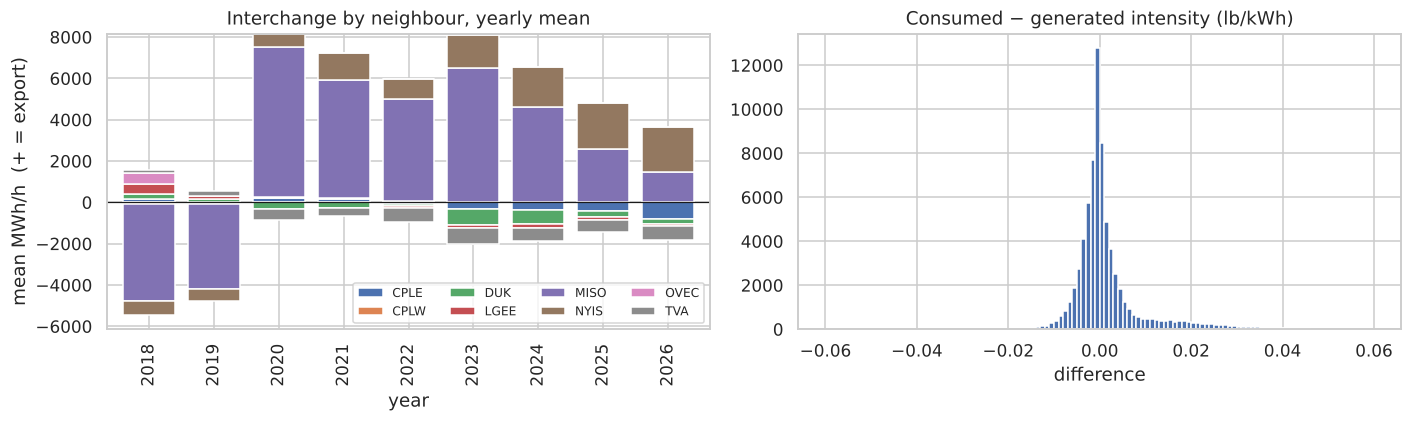

In [11]:
ti = d["Total interchange"]
print(f"Total interchange: mean {ti.mean():.0f} MWh  (positive = net export).  PJM is a net exporter {100*(ti>0).mean():.0f}% of hours.")
print(f"Net trade as % of demand: median |TI|/Demand = {100*(ti.abs()/d['Demand']).median():.1f}%, 95th pct = {100*(ti.abs()/d['Demand']).quantile(.95):.1f}%")

nb_cols = ["CPLE","CPLW","DUK","LGEE","MISO","NYIS","OVEC","TVA"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
d.groupby("year")[nb_cols].mean().plot(kind="bar", stacked=True, ax=ax[0], width=.8)
ax[0].axhline(0, color="k", lw=.8); ax[0].set_ylabel("mean MWh/h  (+ = export)"); ax[0].set_title("Interchange by neighbour, yearly mean")
ax[0].legend(ncol=4, fontsize=8)

ig, ic = d["CO2 Emissions Intensity for Generated Electricity"], d["CO2 Emissions Intensity for Consumed Electricity"]
diff = (ic - ig)
ax[1].hist(diff.dropna(), bins=120, range=(-0.06, 0.06), color="C0")
ax[1].set_title("Consumed − generated intensity (lb/kWh)"); ax[1].set_xlabel("difference")
print(f"consumed - generated: mean {diff.mean():+.4f}, 5th/95th pct {diff.quantile(.05):+.4f}/{diff.quantile(.95):+.4f} lb/kWh")
print(f"correlation between the two intensities: {ig.corr(ic):.4f}")
plt.tight_layout()

Trade is small relative to PJM's size (a few % of demand), so the two intensities almost coincide
(correlation ≈ 0.999, typical difference ≈ ±0.01 lb/kWh on a 0.75 base). **Decision for the proposal:**
use the production-based intensity as the primary target (it only depends on PJM's own reported
generation, which is what we'll forecast), report the consumption-based one as a robustness check, and
state the attribution rule EIA uses for imports. One caveat below (§6): the consumed-intensity column has
a few bad hours where consumption goes negative.

## 6. Data quality

EIA-930 is "as reported" by the BA with EIA's imputation of missing values. The workbook helpfully
exposes both the raw and the imputed/adjusted series. Let's see how often that matters, and find outliers.

In [12]:
base_cols = ["Demand","Net generation","Total interchange","Demand forecast"] + ng_cols
imputed_map = {"Demand":"Imputed demand", "Net generation":"Imputed net generation",
               "Total interchange":"Imputed total interchange",
               **{c: f"Imputed {c.replace('NG: ','')} Gen" for c in ng_cols}}
qa = pd.DataFrame({"missing (raw)": d[base_cols].isna().sum(),
                   "hours EIA imputed": [d[imputed_map[c]].notna().sum() if c in imputed_map else np.nan for c in base_cols]})
qa

,missing (raw),hours EIA imputed
Demand,0,7.0
Net generation,0,4.0
Total interchange,0,4.0
Demand forecast,97,NaN
NG: COL,5,0.0
NG: NG,0,0.0
NG: NUC,5,0.0
NG: OIL,0,0.0
NG: WAT,0,0.0
NG: SUN,5,0.0


In [13]:
# Outliers in the target: extremely low 'Positive Generation' hours produce nonsense intensities.
tgt = "CO2 Emissions Intensity for Generated Electricity"
print(d[tgt].describe().round(3))
sus = d[(d["Positive Generation"] < 0.5*d["Positive Generation"].median()) | (d[tgt] < 0.3) | (d[tgt] > 1.2)]
print(f"\nSuspicious hours: {len(sus)}  ({100*len(sus)/len(d):.3f}% of rows)")
sus[["local","Demand","Net generation","Positive Generation","NG: COL","NG: NG","NG: NUC",tgt]].head(10)

count    71389.000
mean         0.755
std          0.099
min          0.063
25%          0.681
50%          0.749
75%          0.824
max          1.081
Name: CO2 Emissions Intensity for Generated Electricity, dtype: float64

Suspicious hours: 5  (0.007% of rows)


,local,Demand,Net generation,Positive Generation,NG: COL,NG: NG,NG: NUC,CO2 Emissions Intensity for Generated Electricity
63576,2022-10-01 01:00:00-04:00,70238.0,74789.0,287.0,NaN,21.0,NaN,0.069995
63577,2022-10-01 02:00:00-04:00,68175.0,72731.0,287.0,NaN,21.0,NaN,0.069987
63578,2022-10-01 03:00:00-04:00,67376.0,72654.0,287.0,NaN,21.0,NaN,0.070023
63579,2022-10-01 04:00:00-04:00,66624.0,71875.0,306.0,NaN,21.0,NaN,0.066209
63599,2022-10-02 00:00:00-04:00,70670.0,74841.0,325.0,NaN,21.0,NaN,0.062798


In [14]:
# Consumed-side glitches: negative consumed electricity / emissions
bad_cons = d[(d["Consumed Electricity"] <= 0) | (d["CO2 Emissions Consumed"] <= 0)]
print("Hours with non-positive consumed electricity or consumed emissions:", len(bad_cons))
display(bad_cons[["local","Demand","Net generation","Total interchange","Consumed Electricity","CO2 Emissions Consumed"]].head())

# Demand forecast glitches: a handful of hours carry absurd forecasts (~1e8 MWh vs ~1e5 demand)
fc_ratio = d["Demand forecast"] / d["Demand"]
bad_fc = d[(fc_ratio > 2) | (fc_ratio < 0.5)]
print("Hours where demand forecast is off by >2x:", len(bad_fc), "on dates", sorted(set(bad_fc["local"].dt.date)))

Hours with non-positive consumed electricity or consumed emissions: 5


,local,Demand,Net generation,Total interchange,Consumed Electricity,CO2 Emissions Consumed
63576,2022-10-01 01:00:00-04:00,70238.0,74789.0,4554.0,-7715.0,-1475.621074
63577,2022-10-01 02:00:00-04:00,68175.0,72731.0,4560.0,-8242.0,-1506.393360
63578,2022-10-01 03:00:00-04:00,67376.0,72654.0,5281.0,-8442.0,-976.481429
63579,2022-10-01 04:00:00-04:00,66624.0,71875.0,5254.0,-6458.0,-626.030872
63599,2022-10-02 00:00:00-04:00,70670.0,74841.0,4174.0,-6905.0,-1116.743131


Hours where demand forecast is off by >2x: 6 on dates [datetime.date(2019, 12, 11), datetime.date(2020, 4, 10), datetime.date(2020, 7, 24), datetime.date(2021, 10, 18), datetime.date(2021, 10, 19)]


**Preprocessing decisions** (applied below to produce the modelling table `m`):
1. Restrict to **2019-01-01 onward** (first full year with fuel mix; 2018 is partial).
2. Drop hours flagged suspicious above (tiny fraction) → set target / forecast to NaN rather than deleting rows, so the hourly index stays complete.
3. Keep EIA's *adjusted* demand / net generation (raw with EIA's imputations) as features.
4. Build fuel **shares** of positive generation, which are the natural drivers of intensity.

In [15]:
m = d[d["utc"] >= "2019-01-01"].copy()
m["ci"]  = m[tgt].where(~m.index.isin(sus.index))             # production-based target, lb/kWh
m["ci_cons"] = m["CO2 Emissions Intensity for Consumed Electricity"].where(~m.index.isin(bad_cons.index))
m["ci_g"] = m["ci"] * 453.592                                   # g CO2 / kWh, for readability
for c in ng_cols:
    m["share_"+c.replace("NG: ","").lower()] = m[c].clip(lower=0) / m["Positive Generation"]
m["share_renew"] = m[["share_wat","share_sun","share_wnd"]].sum(axis=1)
m["share_fossil"] = m[["share_col","share_ng","share_oil"]].sum(axis=1)
m.loc[m.index.isin(bad_fc.index), "Demand forecast"] = np.nan
m["demand_fc_err"] = m["Demand forecast"] - m["Demand"]
m = m.set_index("utc")
print(m.shape, "   target missing:", m["ci"].isna().sum(), "hours")
m[["local","ci","ci_g","share_col","share_ng","share_nuc","share_renew","Demand","Demand forecast"]].head()

(68683, 129)    target missing: 5 hours


,local,ci,ci_g,share_col,share_ng,share_nuc,share_renew,Demand,Demand forecast
utc,,,,,,,,,
2019-01-01 00:00:00+00:00,2018-12-31 19:00:00-05:00,0.757178,343.449693,0.248623,0.239742,0.400069,0.102580,94016.0,100991.0
2019-01-01 01:00:00+00:00,2018-12-31 20:00:00-05:00,0.725207,328.948049,0.235984,0.234208,0.416574,0.103996,90385.0,99187.0
2019-01-01 02:00:00+00:00,2018-12-31 21:00:00-05:00,0.701524,318.205663,0.224230,0.235681,0.432994,0.097416,86724.0,97091.0
2019-01-01 03:00:00+00:00,2018-12-31 22:00:00-05:00,0.678994,307.986354,0.222630,0.213572,0.456552,0.097032,82978.0,93374.0
2019-01-01 04:00:00+00:00,2018-12-31 23:00:00-05:00,0.669397,303.632909,0.224411,0.198263,0.470927,0.096017,79536.0,87684.0


> **Note on cleaning / preprocessing (for whoever merges this with the ERCOT and PJM-interchange data).**
> Very little cleaning was done here, and that was deliberate: the EIA-930 workbook arrives already
> cleaned by EIA (imputed gaps, adjusted demand/generation, complete hourly index, no duplicates).
> The full list of what *was* done to get from the raw sheet to `m` is:
>
> * parse `UTC time` as the key and derive local hour / date in `America/New_York` (never EIA's `Hour` column);
> * drop fuel columns that are entirely empty for PJM (GEO, PS, SNB, WNB, BAT, OES, UES, UNK);
> * restrict to 2019-01-01 onward (fuel mix / CO₂ columns only start mid-2018);
> * set **11 hours** to NaN instead of deleting them: 5 hours (2022-10-01/02) with broken positive generation
>   → `ci` and `ci_cons` NaN; 6 hours over 5 days (2019–2021) with absurd demand forecasts → `Demand forecast` NaN;
> * derive features: fuel shares of positive generation, `ci_g` (g/kWh), `demand_fc_err`, calendar columns.
>
> What was **not** done: no imputation of our own, no outlier removal beyond the 11 hours above, no scaling,
> no resampling, no row deletion, no train/test split, no encoding of categoricals. All of that is left to the
> modelling stage, and should be decided jointly once the ERCOT and interchange tables are in the same shape
> (hourly UTC index, one row per hour, intensity in lb/kWh with `_g` for g/kWh).

## 7. EDA of the target

Four views: overall distribution, long-run trend, seasonal pattern, and the within-day (diurnal) profile
that the whole project hinges on.

count    68678.0
mean       341.2
std         44.2
min        207.6
25%        307.8
50%        337.6
75%        371.8
max        487.4
Name: ci_g, dtype: float64


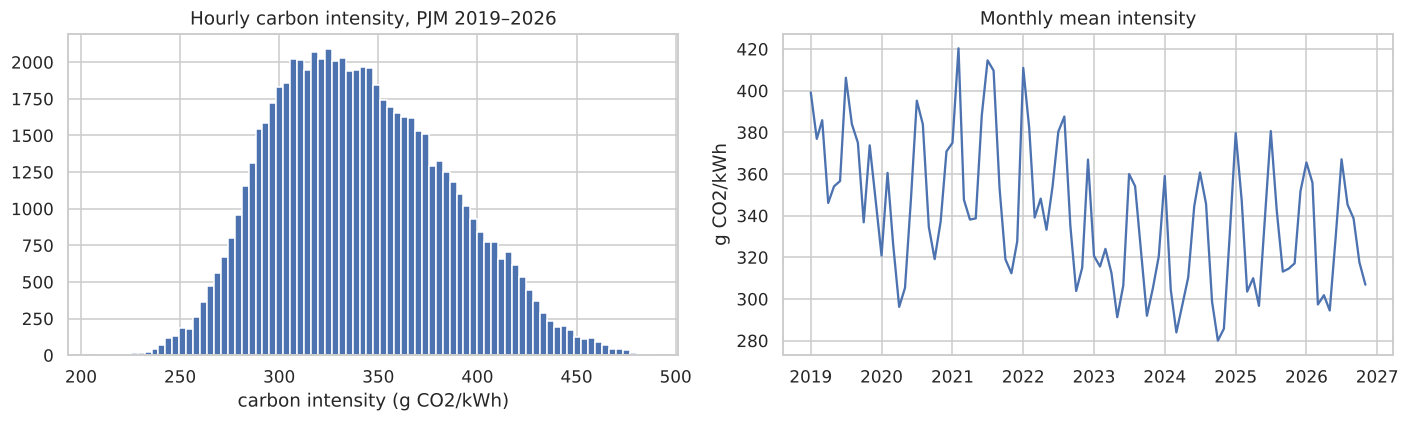

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(m["ci_g"].dropna(), bins=80, color="C0")
ax[0].set_xlabel("carbon intensity (g CO2/kWh)"); ax[0].set_title("Hourly carbon intensity, PJM 2019–2026")
monthly = m["ci_g"].resample("MS").mean()
ax[1].plot(monthly.index, monthly.values, color="C0")
ax[1].set_title("Monthly mean intensity"); ax[1].set_ylabel("g CO2/kWh")
plt.tight_layout()
print(m["ci_g"].describe().round(1))

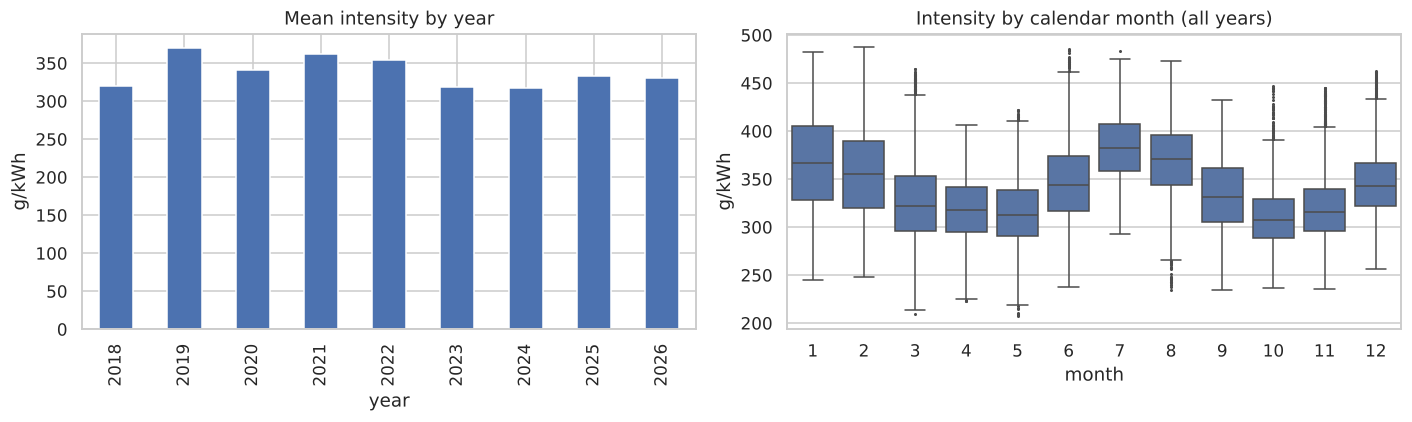

In [17]:
# Yearly trend and seasonality
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
m.groupby("year")["ci_g"].mean().plot(kind="bar", ax=ax[0], color="C0"); ax[0].set_title("Mean intensity by year"); ax[0].set_ylabel("g/kWh")
sns.boxplot(data=m.reset_index(), x="month", y="ci_g", ax=ax[1], color="C0", fliersize=1)
ax[1].set_title("Intensity by calendar month (all years)"); ax[1].set_ylabel("g/kWh")
plt.tight_layout()

### The diurnal profile — is there a daily low-carbon window?

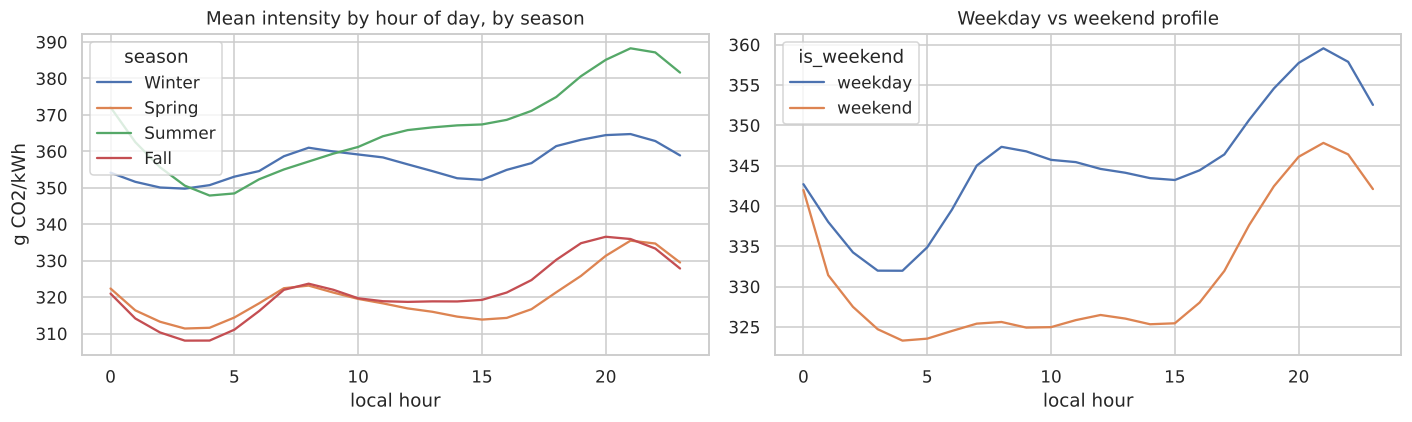

In [18]:
season = pd.cut(m["month"], [0,2,5,8,11,12], labels=["Winter","Spring","Summer","Fall","Winter2"]).astype(str).replace({"Winter2":"Winter"})
m["season"] = season
prof = m.groupby(["season","hour"])["ci_g"].mean().unstack(0)[["Winter","Spring","Summer","Fall"]]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
prof.plot(ax=ax[0]); ax[0].set_title("Mean intensity by hour of day, by season"); ax[0].set_xlabel("local hour"); ax[0].set_ylabel("g CO2/kWh")
m.groupby(["is_weekend","hour"])["ci_g"].mean().unstack(0).rename(columns={False:"weekday",True:"weekend"}).plot(ax=ax[1])
ax[1].set_title("Weekday vs weekend profile"); ax[1].set_xlabel("local hour")
plt.tight_layout()

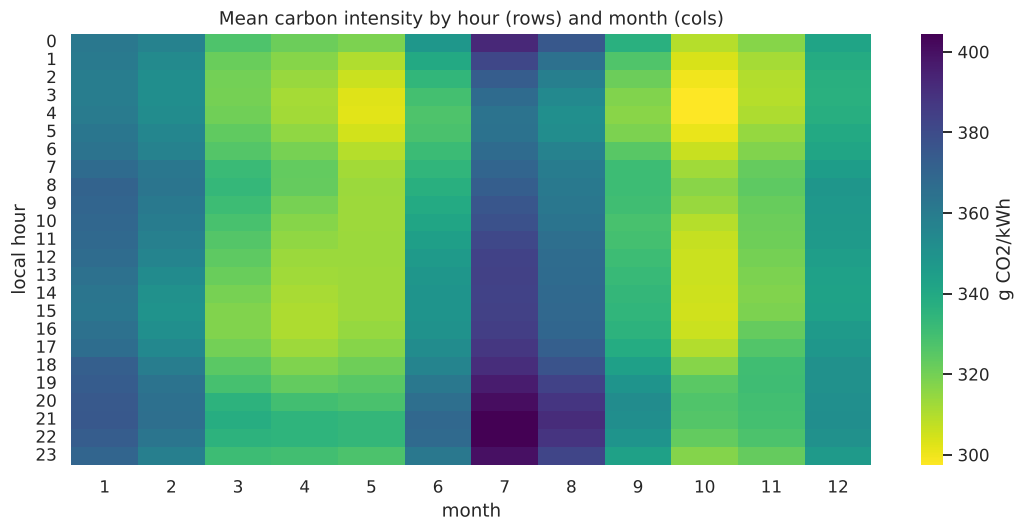

In [19]:
# Hour x month heat map of mean intensity (what a scheduler would see 'on average')
hm = m.pivot_table(index="hour", columns="month", values="ci_g", aggfunc="mean")
plt.figure(figsize=(10, 5))
sns.heatmap(hm, cmap="viridis_r", cbar_kws={"label": "g CO2/kWh"})
plt.title("Mean carbon intensity by hour (rows) and month (cols)"); plt.ylabel("local hour")
plt.tight_layout()

Observations to carry into the write-up:
* The daily shape is modest (±5 % around the day's mean) but consistent: intensity is **lowest around
  3–4 am local** (low demand → nuclear + wind are a bigger share), has a **secondary dip around 2–4 pm in
  spring/fall/winter** (solar), and peaks in the **evening ramp (~9 pm)** when gas and coal fill in.
  Summer is different: it rises almost monotonically from the night-time trough to the evening peak.
* Seasonality is strong (winter/summer high, spring/fall low) and there is a slow downward trend as coal
  retires — the model will need to handle non-stationarity (recent-window training, trend/season features).
* Weekends sit ~15–20 g/kWh lower than weekdays at every hour, and the weekday daytime bump is absent.

## 8. What drives intensity?

Intensity is mechanically a weighted average of fuel factors, so fuel *shares* explain it almost perfectly.
The interesting question for forecasting is what drives the shares: demand level, wind, solar, and the
coal/gas dispatch order. Let's look at both layers.

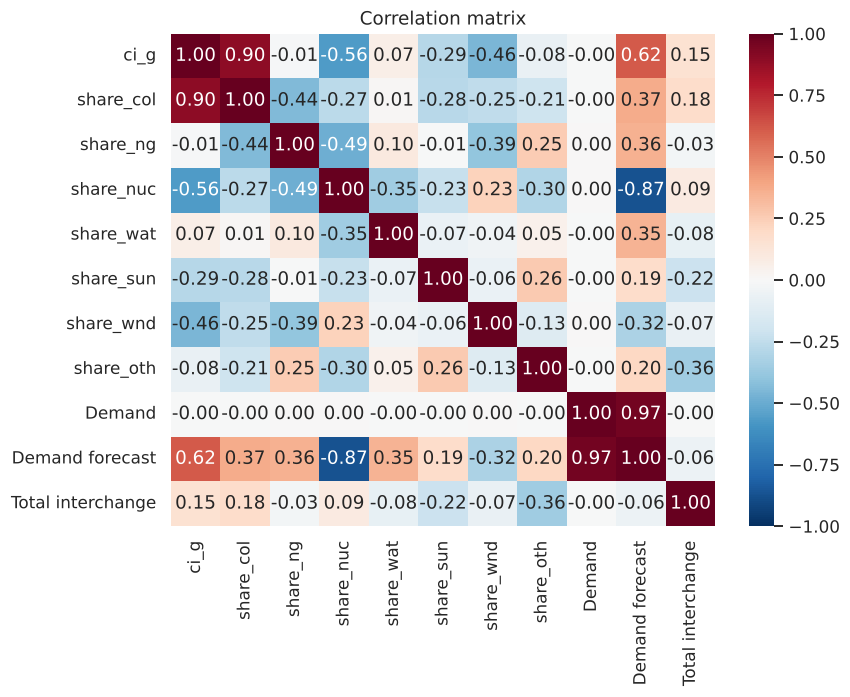

In [20]:
feat = ["ci_g","share_col","share_ng","share_nuc","share_wat","share_sun","share_wnd","share_oth","Demand","Demand forecast","Total interchange"]
corr = m[feat].corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix"); plt.tight_layout()

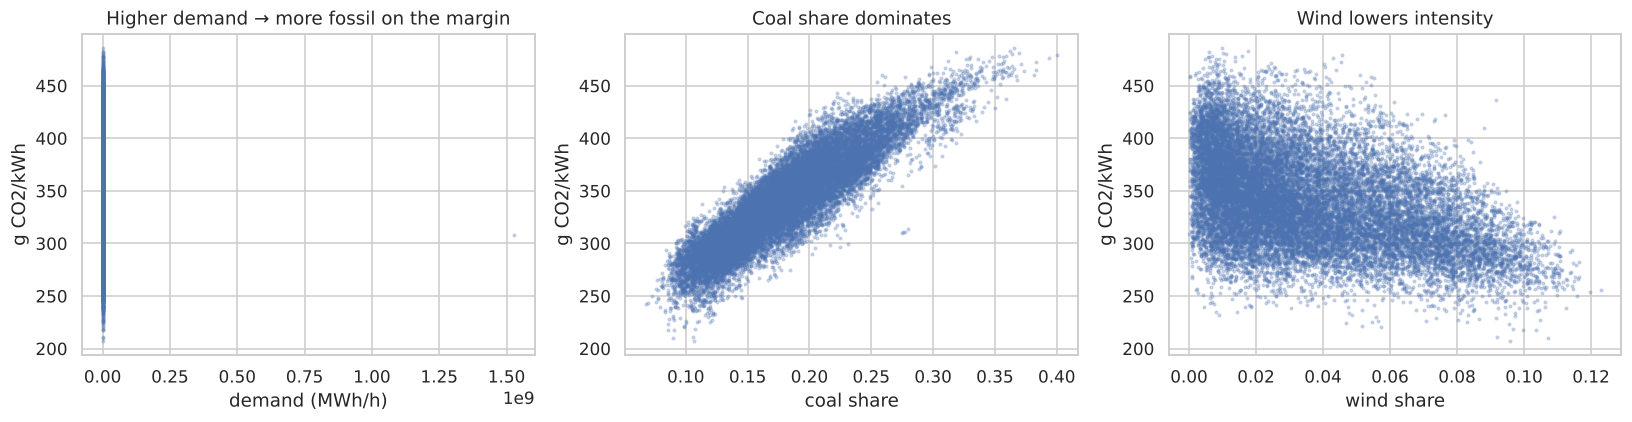

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
s = m.sample(20000, random_state=0)
for a, x, lab in zip(ax, ["Demand","share_col","share_wnd"], ["demand (MWh/h)","coal share","wind share"]):
    a.scatter(s[x], s["ci_g"], s=3, alpha=.25); a.set_xlabel(lab); a.set_ylabel("g CO2/kWh")
ax[0].set_title("Higher demand → more fossil on the margin"); ax[1].set_title("Coal share dominates"); ax[2].set_title("Wind lowers intensity")
plt.tight_layout()

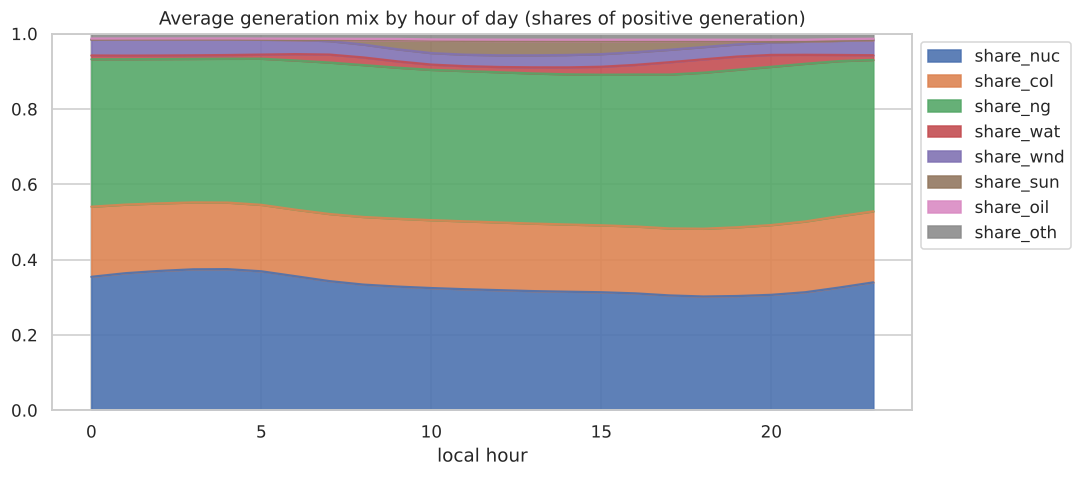

In [22]:
# Average fuel mix by hour of day (stacked shares) — shows WHY the diurnal shape exists
mix = m.groupby("hour")[["share_nuc","share_col","share_ng","share_wat","share_wnd","share_sun","share_oil","share_oth"]].mean()
mix.plot(kind="area", stacked=True, figsize=(10, 4.5), alpha=.9)
plt.title("Average generation mix by hour of day (shares of positive generation)"); plt.xlabel("local hour"); plt.ylim(0,1)
plt.legend(loc="upper left", bbox_to_anchor=(1,1)); plt.tight_layout()

## 9. How much is there to gain? Within-day spread

If every hour of a day had the same intensity, scheduling would be pointless. The key quantity is the
spread between a day's best hours and its average (or its worst hours).

          std  range_%_of_mean  gain_best4_vs_mean_%
count  2867.0           2873.0                2873.0
mean     15.0             14.9                   6.3
std       6.4              5.6                   3.0
min       0.1              0.0                   0.0
25%      10.1             10.8                   4.0
50%      13.8             14.3                   5.7
75%      18.8             18.3                   8.2
max      45.1             46.8                  21.6


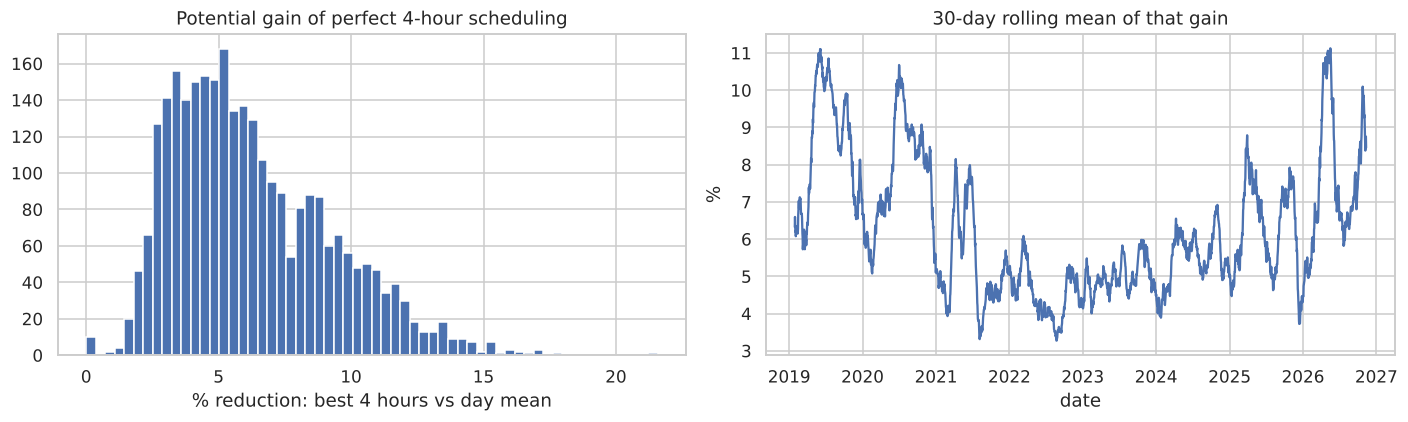

In [23]:
daily = m.groupby("date")["ci_g"].agg(["mean","min","max","std", lambda s: s.nsmallest(4).mean()])
daily.columns = ["mean","min","max","std","best4h_mean"]
daily["gain_best4_vs_mean_%"] = 100*(1 - daily["best4h_mean"]/daily["mean"])
daily["range_%_of_mean"] = 100*(daily["max"]-daily["min"])/daily["mean"]
print(daily[["std","range_%_of_mean","gain_best4_vs_mean_%"]].describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(daily["gain_best4_vs_mean_%"].dropna(), bins=60, color="C0")
ax[0].set_xlabel("% reduction: best 4 hours vs day mean"); ax[0].set_title("Potential gain of perfect 4-hour scheduling")
daily["gain_best4_vs_mean_%"].rolling(30).mean().plot(ax=ax[1], color="C0")
ax[1].set_title("30-day rolling mean of that gain"); ax[1].set_ylabel("%")
plt.tight_layout()

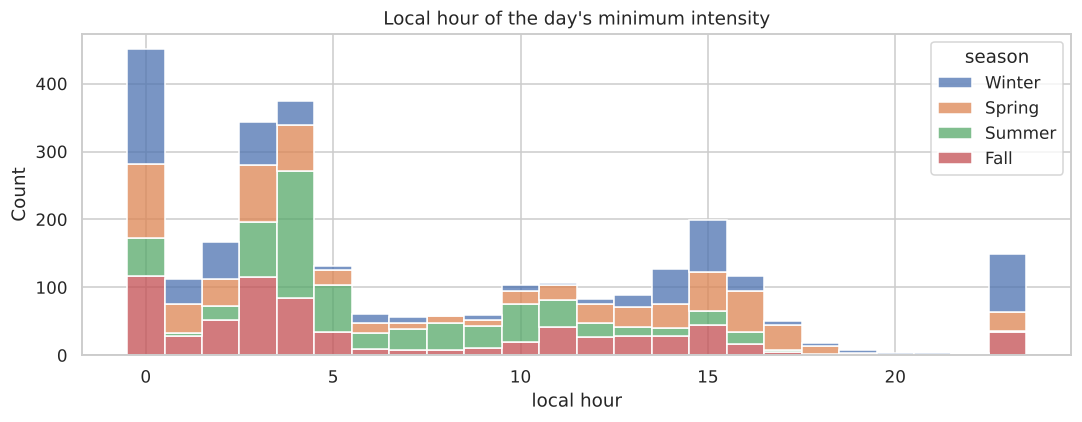

In [24]:
# Where in the day do the lowest hours fall? Distribution of the argmin hour, by season.
argmin_hour = m.groupby("date").apply(lambda g: g.loc[g["ci_g"].idxmin(), "hour"] if g["ci_g"].notna().any() else np.nan)
argmin_hour = argmin_hour.rename("argmin_hour").to_frame().join(m.groupby("date")["season"].first())
plt.figure(figsize=(10, 4))
sns.histplot(data=argmin_hour, x="argmin_hour", hue="season", bins=24, multiple="stack", discrete=True)
plt.title("Local hour of the day's minimum intensity"); plt.xlabel("local hour"); plt.tight_layout()

The headline: a perfect-foresight 4-hour schedule beats "run at an average hour of the day" by about
**6 % on a typical day (median ≈ 5.7 %, IQR 4–8 %)**, with a tail of days above 12 % (windy spring/fall
days). That is the ceiling any forecast-based scheduler can reach — a useful number for framing the
project. The minimum hour is bimodal (early morning most days, mid-afternoon on a substantial minority,
plus late-evening in winter), which is exactly what makes it worth *predicting* rather than hard-coding
a fixed window.

## 10. Naive day-ahead baselines and a first scheduling simulation

Before any ML, two questions: (a) how accurate are trivial forecasts of tomorrow's hourly intensity,
and (b) how much of the perfect-foresight gain do they capture? Baselines:
* **Persistence** — tomorrow's profile = today's (lag 24 h)
* **Weekly persistence** — same hour one week ago
* **Climatology** — mean profile for this month × hour × weekday/weekend from the *training* years

In [25]:
y = m["ci_g"]
pred = pd.DataFrame({"y": y})
pred["persist_24h"] = y.shift(24)
pred["persist_7d"]  = y.shift(24*7)
clim = m[m["year"] <= 2023].groupby(["month","hour","is_weekend"])["ci_g"].mean()
pred["climatology"] = pd.MultiIndex.from_frame(m[["month","hour","is_weekend"]]).map(clim)
pred["persist_avg"] = pred[["persist_24h","persist_7d"]].mean(axis=1)

test = pred[m["year"] >= 2024].dropna()
def mae(a,b): return (a-b).abs().mean()
summary = pd.DataFrame({
    "MAE (g/kWh)": {c: mae(test["y"], test[c]) for c in ["persist_24h","persist_7d","climatology","persist_avg"]},
    "MAPE (%)":    {c: 100*((test["y"]-test[c]).abs()/test["y"]).mean() for c in ["persist_24h","persist_7d","climatology","persist_avg"]},
})
print("Evaluated on 2024–2026,", len(test), "hours")
summary.round(2)

Evaluated on 2024–2026, 24950 hours


,MAE (g/kWh),MAPE (%)
persist_24h,16.23,5.09
persist_7d,28.76,8.82
climatology,34.68,11.26
persist_avg,18.73,5.79


In [26]:
# Does the baseline pick the right hours?  Scheduling simulation: a 4-hour flexible job, each day.
def simulate(block, k=4, pred_col="persist_24h"):
    out = []
    for date, g in block.groupby(block.index.tz_convert("America/New_York").date):
        g = g.dropna(subset=["y", pred_col])
        if len(g) < 24: continue
        actual = g["y"].values
        run_9to5  = actual[9:9+k].mean()                             # 'submit at 9 am and run immediately'
        oracle    = np.sort(actual)[:k].mean()
        chosen    = actual[np.argsort(g[pred_col].values)[:k]].mean()
        out.append({"date": date, "run_9am": run_9to5, "oracle": oracle, "pred": chosen, "day_mean": actual.mean()})
    return pd.DataFrame(out).set_index("date")

res = {c: simulate(test, pred_col=c) for c in ["persist_24h","persist_7d","climatology","persist_avg"]}
tbl = pd.DataFrame({c: {"emissions vs run-at-9am (%)": 100*(r["pred"].mean()/r["run_9am"].mean()-1),
                        "emissions vs day mean (%)":   100*(r["pred"].mean()/r["day_mean"].mean()-1),
                        "oracle vs day mean (%)":      100*(r["oracle"].mean()/r["day_mean"].mean()-1),
                        "share of oracle gain captured (%)": 100*(r["day_mean"].mean()-r["pred"].mean())/(r["day_mean"].mean()-r["oracle"].mean())}
                    for c, r in res.items()}).T
tbl.round(1)

,emissions vs run-at-9am (%),emissions vs day mean (%),oracle vs day mean (%),share of oracle gain captured (%)
persist_24h,-1.0,-4.0,-6.3,62.6
persist_7d,-0.5,-3.5,-6.3,55.1
climatology,2.1,-1.0,-6.3,15.9
persist_avg,-1.3,-4.3,-6.3,67.9


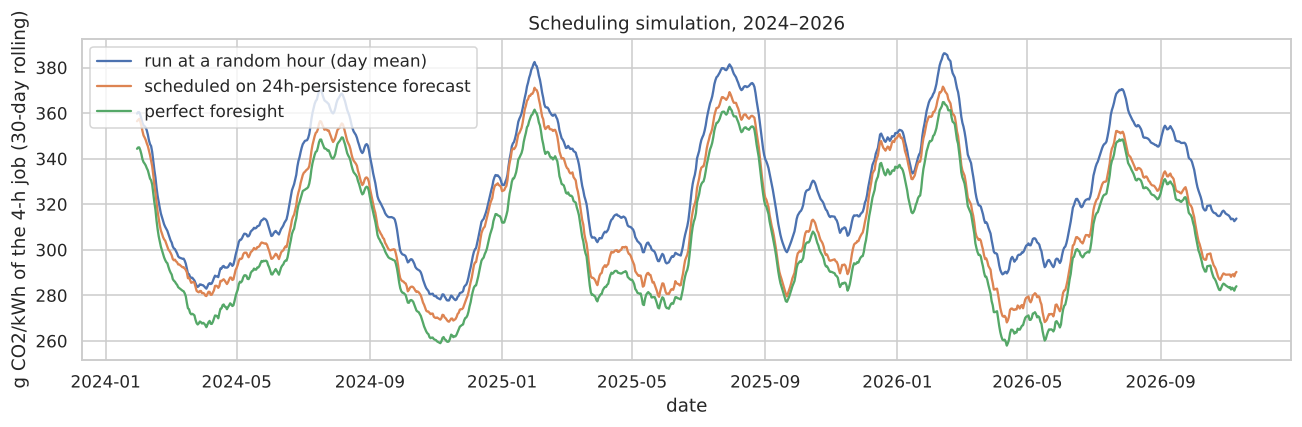

In [27]:
r = res["persist_24h"]
fig, ax = plt.subplots(figsize=(12, 4))
for c, lab in [("day_mean","run at a random hour (day mean)"),("pred","scheduled on 24h-persistence forecast"),("oracle","perfect foresight")]:
    r[c].rolling(30).mean().plot(ax=ax, label=lab)
ax.set_ylabel("g CO2/kWh of the 4-h job (30-day rolling)"); ax.set_title("Scheduling simulation, 2024–2026"); ax.legend()
plt.tight_layout()

Even the dumbest forecast (copy yesterday, MAPE ≈ 5 %) captures roughly **60 % of the perfect-foresight
gain**, because the daily shape is persistent; climatology does far worse (it knows the average shape but not
today's wind/coal situation). That sets the bar for the project: a learned model must beat
persistence on **ranking the hours**, not just on MAE. Good evaluation metrics to adopt:
MAE/MAPE of the hourly forecast, Spearman rank correlation within each day, and
"share of oracle gain captured" for the scheduling task.

### Bonus feature: EIA's day-ahead demand forecast is in the file
`Demand forecast` is the BA's own day-ahead demand forecast — a legitimately available-at-prediction-time
input, and demand is a strong driver of intensity.

Demand forecast error (2019+, glitches removed): MAE 3316 MWh (3.60% MAPE), bias -1144 MWh


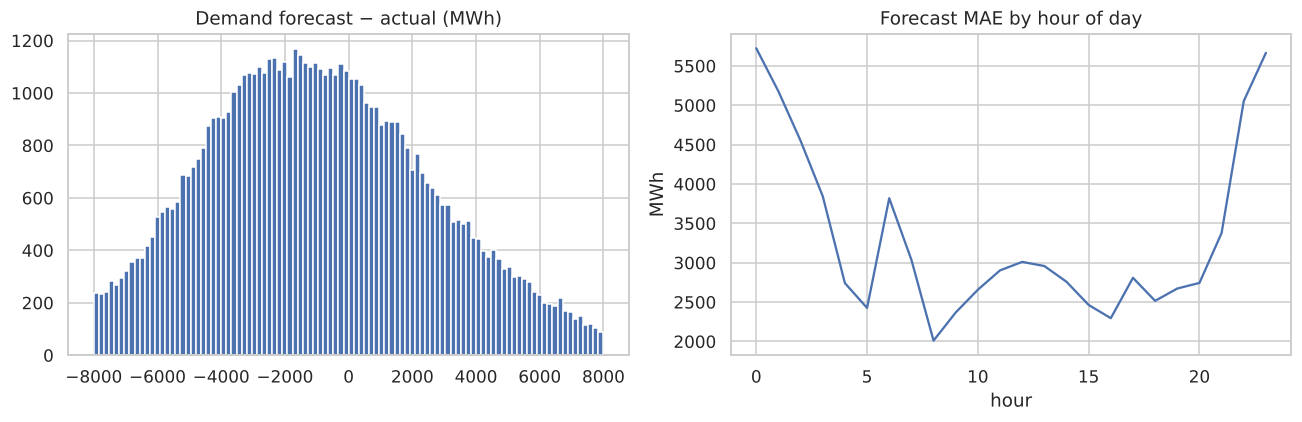

In [28]:
e = m["demand_fc_err"].dropna()
print(f"Demand forecast error (2019+, glitches removed): MAE {e.abs().mean():.0f} MWh "
      f"({100*(e.abs()/m.loc[e.index,'Demand']).mean():.2f}% MAPE), bias {e.mean():+.0f} MWh")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(e, bins=100, range=(-8000, 8000), color="C0"); ax[0].set_title("Demand forecast − actual (MWh)")
m.groupby("hour")["demand_fc_err"].apply(lambda s: s.abs().mean()).plot(ax=ax[1], color="C0")
ax[1].set_title("Forecast MAE by hour of day"); ax[1].set_ylabel("MWh")
plt.tight_layout()

## 11. Takeaways and next steps

**What we learned**
* EIA-930 for PJM gives a complete, hourly, 2019→present table with generation by fuel, interchange with
  each neighbour, demand, a day-ahead demand forecast, and EIA's own CO₂ accounting.
* Units resolved: EIA's per-fuel factors are lb CO₂/kWh (heat rate already folded in); emissions are in
  metric tons; intensities in lb/kWh. We can reproduce EIA's numbers exactly from the raw components, and
  the factors agree with (kg/MMBtu fuel factor) × (MMBtu/MWh heat rate) to within a few percent.
* PJM is a net exporter ~97 % of hours and trade is only ~4 % of demand, so imports/exports move the
  intensity by ~±1–2 %; production-based is the primary target, consumption-based the robustness check.
* The target has strong seasonal and diurnal structure, a downward trend, and a within-day spread that gives a
  perfect-foresight 4-hour scheduler ~6 % lower emissions than an average hour (more on windy days).
* 24-hour persistence (MAPE ≈ 5 %) already captures ~60 % of that gain; the model must beat it on *ranking* hours within a day.
* Data quality is good: complete hourly UTC index, no duplicates, 5 bad target hours (Oct 2022) and 6 hours of garbage demand forecasts spread over 5 days (2019–2021).

**Open questions / next steps**
1. Add NOAA hourly weather (temperature, wind speed, cloud cover) at a few PJM locations — the main
   exogenous driver of wind/solar output and demand. Check whether it improves on persistence.
2. Decide the forecast formulation: 24 separate regressions (one per hour), a single model with hour as a
   feature, or a direct multi-output model. Evaluate with rolling-origin (time-series) CV, never random splits.
3. Choose the scheduling evaluation: job length (1 h, 4 h, 8 h), deadline, and whether the job must be contiguous.
4. Treat the few bad hours and the 2024-era mix shift (coal retirements, solar growth) explicitly — recent
   data likely deserves more weight.
5. Reproduce this for a second BA (e.g. MISO or CAISO, where solar makes the daily shape much stronger) to show generality.